# Stereo: rectification, semi-global matching and depth

A calibrated stereo pair is the simplest metric depth sensor a robot can carry: two
cameras, a known baseline, and a 1-D search along image rows. This notebook works through
the whole chain on the **Middlebury 2014 / MiddEval3** benchmark (quarter resolution, 15
training scenes with sub-pixel ground-truth disparity):

**What you will learn**

* why *rectification* turns the 2-D correspondence search into a 1-D search along rows,
  and how to measure whether a pair is rectified (vertical disparity of matches);
* how to re-rectify a mis-aligned rig, both **calibrated** (`cv2.stereoRectify`, Bouguet)
  and **uncalibrated** (`cv2.stereoRectifyUncalibrated`, Hartley, from $F$ only);
* block matching (`StereoBM`) vs semi-global matching (`StereoSGBM`), left-right
  consistency checks and hole filling, evaluated with the standard **bad-x** and **EPE**
  metrics;
* disparity → metric depth → point cloud, and why depth error grows with $Z^2$.

**Prerequisites:** notebook 01 (epipolar geometry). **Data:** `make data-09_multiview_geometry`
(Middlebury MiddEval3 `-data-Q` + `-GT0-Q`, 45 MB). **Runtime:** under 1 minute, CPU only.

## Setup

In [1]:
# --- Setup: imports, seeding, repo-relative paths, plotting style ---
# All stereo helpers (PFM reader, SGBM wrapper, metrics, rectification) live in mvgeo.py.
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cvlab.device
from cvlab import viz
from cvlab.geometry import so3_exp
from cvlab.io import project_dir, save_json
from cvlab.pointcloud import depth_to_points

PROJECT = "09_multiview_geometry"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import mvgeo as M  # noqa: E402

device = cvlab.device.setup(seed=0)
viz.set_style()
RESULTS_DIR = project_dir(PROJECT) / "results"
SCENES = M.list_middlebury_scenes("trainingQ")
print(f"{len(SCENES)} MiddEval3 training scenes (quarter resolution): {', '.join(SCENES)}")

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
15 MiddEval3 training scenes (quarter resolution): Adirondack, ArtL, Jadeplant, Motorcycle, MotorcycleE, Piano, PianoL, Pipes, Playroom, Playtable, PlaytableP, Recycle, Shelves, Teddy, Vintage


## 1. Rectified stereo geometry

In a rectified pair both image planes are coplanar and the baseline is parallel to the
image rows, so a scene point appears on the **same row** in both images, shifted by the
disparity $d = u_l - u_r$. Similar triangles give

$$Z = \frac{f\,B}{d + d_\text{offs}},$$

with focal length $f$ [px], baseline $B$ [mm] and $d_\text{offs} = c_{x,r} - c_{x,l}$, the
difference of the principal points (Middlebury keeps the original principal points,
so $d_\text{offs} \ne 0$). Each scene ships a `calib.txt` with `cam0`, `cam1`, `doffs`,
`baseline` and `ndisp` (an upper bound on the disparity range).

image 741x497 | f = 999.4 px | baseline = 193.0 mm | doffs = 32.78 px | ndisp = 70
GT disparity range 9.2..62.9 px | non-occluded GT pixels: 86.6%
GT depth range 2.02..4.60 m


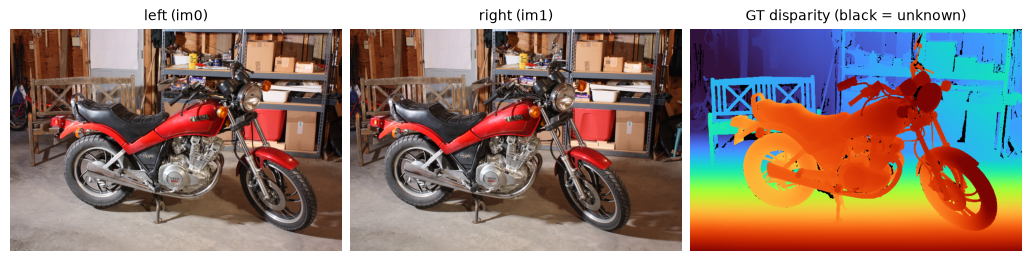

In [2]:
# --- Load the Motorcycle pair, its calibration and ground-truth disparity ---
# GT disparities are float PFM images; unknown pixels are NaN. mask0nocc = non-occluded.
pair = M.load_middlebury("Motorcycle")
c = pair.calib
f, B, doffs = pair.f, c["baseline"], c["doffs"]
H, W = pair.left.shape[:2]
print(f"image {W}x{H} | f = {f:.1f} px | baseline = {B:.1f} mm | doffs = {doffs:.2f} px | "
      f"ndisp = {pair.ndisp}")
print(f"GT disparity range {np.nanmin(pair.gt):.1f}..{np.nanmax(pair.gt):.1f} px | "
      f"non-occluded GT pixels: {pair.nocc.mean():.1%}")
gt_depth = M.disparity_to_depth(pair.gt, f, B, doffs) / 1000.0  # metres
print(f"GT depth range {np.nanmin(gt_depth):.2f}..{np.nanmax(gt_depth):.2f} m")
fig = viz.show_images([pair.left, pair.right, viz.colorize_depth(pair.gt)],
                      ["left (im0)", "right (im1)", "GT disparity (black = unknown)"],
                      ncols=3, size=3.4)
plt.show()

### Is the pair really rectified?

A direct test: match features between the two images (SIFT, verified by a generic
fundamental-matrix RANSAC that does *not* assume rectification) and look at the vertical
offset $dy = v_l - v_r$ of the inlier matches. For a rectified pair $dy \approx 0$
everywhere; Middlebury's calibration file reports its own residual `dyavg`.

In [3]:
# --- Vertical disparity of verified matches on the original pair ---
vd_orig = M.vertical_disparity(pair.left, pair.right)
print(f"{vd_orig['n']} verified matches | median |dy| = {vd_orig['median_abs_dy']:.2f} px | "
      f"90th percentile = {vd_orig['p90_abs_dy']:.2f} px | calib.txt dyavg = {c['dyavg']}")

927 verified matches | median |dy| = 0.32 px | 90th percentile = 0.68 px | calib.txt dyavg = 0.23


## 2. Breaking and re-rectifying the rig

To see rectification at work we simulate a rig whose right camera has been knocked
slightly out of alignment: we rotate it by $R_\text{err}$ (1°, −2°, 1.5° about x, y, z).
For a rotation about the camera centre the new image is an exact homography of the old
one, $x' \sim K R_\text{err} K^{-1} x$, so we can render it without knowing depth.

The new relative pose is $X_r' = R_\text{err}(X_l + t)$, i.e. $R = R_\text{err}$ and
$T = R_\text{err}\,t$ with $t = (-B, 0, 0)^\top$.

* **Calibrated (Bouguet, `cv2.stereoRectify`).** With $K_l, K_r, R, T$ known, each camera
  is rotated by half of the relative rotation, and then both are rotated so that their
  x-axes align with the baseline. The result is a pair of rectifying rotations
  $R_1, R_2$ and new projection matrices $P_1, P_2$; `initUndistortRectifyMap` + `remap`
  resample the images. $Q$ maps $(u, v, d, 1)$ to 3-D, so metric depth survives.
* **Uncalibrated (Hartley, `cv2.stereoRectifyUncalibrated`).** Only $F$ and matches are
  used. Two homographies $H_1, H_2$ send the epipoles to infinity along the x-axis while
  minimising distortion. Rows align, but without $K$ the depth is only defined up to a
  projective transformation.

In [4]:
# --- Simulate a mis-aligned right camera and re-rectify it in two ways ---
K0, K1 = c["cam0"], c["cam1"]
R_err = so3_exp(np.deg2rad([1.0, -2.0, 1.5]))
right_bad = M.warp_rotation(pair.right, K1, R_err)
vd_bad = M.vertical_disparity(pair.left, right_bad)

t_lr = np.array([-B, 0.0, 0.0])  # X_r = X_l + t for the original rectified rig [mm]
rect = M.rectify_calibrated(pair.left, right_bad, K0, K1, R_err, R_err @ t_lr)
vd_cal = M.vertical_disparity(rect["left"], rect["right"])
unc = M.rectify_uncalibrated(pair.left, right_bad, vd_bad["x1"], vd_bad["x2"], vd_bad["F"])
vd_unc = M.vertical_disparity(unc["left"], unc["right"])
print("rectifying rotation of the left camera R1 (deg):",
      np.rad2deg(np.linalg.norm(cv2.Rodrigues(rect["R1"])[0])).round(2),
      "| right R2 (deg):", np.rad2deg(np.linalg.norm(cv2.Rodrigues(rect["R2"])[0])).round(2))
print("new focal length after rectification (alpha=0 crop):", rect["P1"][0, 0].round(1), "px")
for name, vd in [("original", vd_orig), ("rotated right camera", vd_bad),
                 ("calibrated re-rectification", vd_cal), ("uncalibrated re-rectification", vd_unc)]:
    print(f"{name:32s} median |dy| = {vd['median_abs_dy']:6.2f} px  (n = {vd['n']})")

rectifying rotation of the left camera R1 (deg): 0.5 | right R2 (deg): 2.55
new focal length after rectification (alpha=0 crop): 1088.7 px
original                         median |dy| =   0.32 px  (n = 927)
rotated right camera             median |dy| =  17.32 px  (n = 801)
calibrated re-rectification      median |dy| =   0.35 px  (n = 913)
uncalibrated re-rectification    median |dy| =   0.15 px  (n = 845)


Below, the same scene rows are overlaid on both images (horizontal lines every 40 px).
Before re-rectification, features on a line in the left image sit on a different row in
the right image; afterwards they line up again.

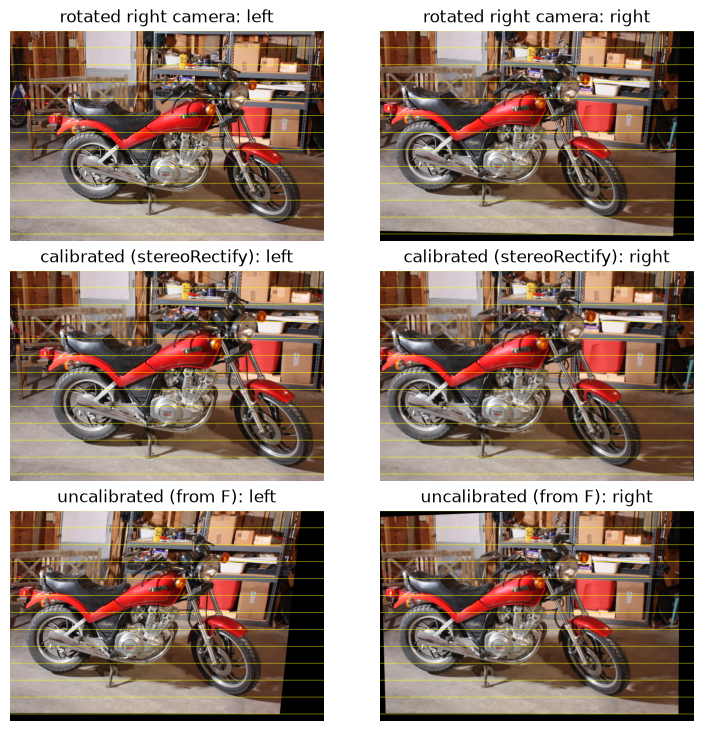

In [5]:
# --- Visual check: horizontal guide lines over the image pairs ---
def with_rows(img, step=40):
    out = img.copy()
    out[::step] = (255, 255, 0)
    return out

rows = [("rotated right camera", pair.left, right_bad),
        ("calibrated (stereoRectify)", rect["left"], rect["right"]),
        ("uncalibrated (from F)", unc["left"], unc["right"])]
fig, axes = plt.subplots(3, 2, figsize=(7.4, 7.2))
for r, (name, a, b) in enumerate(rows):
    for k, img in enumerate((a, b)):
        axes[r, k].imshow(with_rows(img))
        axes[r, k].set_title(f"{name}: {'left' if k == 0 else 'right'}")
        axes[r, k].axis("off")
viz.savefig(fig, PROJECT, "rectification_pairs")
plt.show()

Does rectification restore *metric* depth? We run SGBM on each pair (method details in
section 3), convert the calibrated result back to depth in the **original** left camera
($X_\text{rect} \sim Q\,[u, v, d, 1]^\top$, $X_l = R_1^\top X_\text{rect}$, project with $K_0$)
and compare with the ground-truth depth on non-occluded pixels. The uncalibrated pair
gives a disparity map but no metric depth, so only its density is reported.

search range calibrated: 40..120 px | uncalibrated: -30..50 px


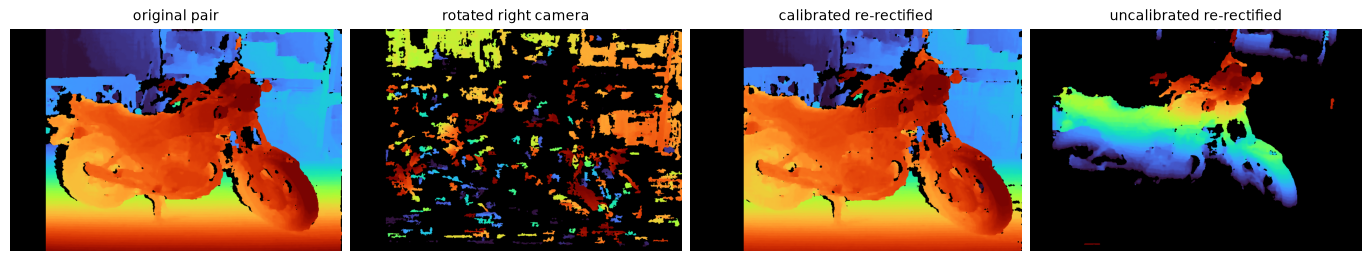

,pair,median |dy| [px],p90 |dy| [px],SGBM density,depth AbsRel,depth within 1%,GT pixels covered
0,original (rectified by Middlebury),0.3156,0.6831,0.8368,0.0095,0.9138,0.9024
1,rotated right camera,17.3183,24.0505,0.2508,0.4145,0.0057,0.2587
2,calibrated re-rectification,0.3459,0.7804,0.7878,0.0096,0.9065,0.7147
3,uncalibrated re-rectification,0.1479,0.5885,0.8213,NaN,NaN,NaN


In [6]:
# --- SGBM on each pair; metric depth error where calibration is available ---
# Rectification changes the disparity range (stereoRectify makes the principal points equal,
# which adds doffs; Hartley's homographies can even make disparities negative), so the
# search range [min_disp, min_disp + ndisp) is taken from the verified matches of each pair.
rng_cal = M.disparity_search_range(vd_cal["x1"], vd_cal["x2"])
rng_unc = M.disparity_search_range(vd_unc["x1"], vd_unc["x2"])
print(f"search range calibrated: {rng_cal[0]}..{sum(rng_cal)} px | "
      f"uncalibrated: {rng_unc[0]}..{sum(rng_unc)} px")
d_orig = M.stereo_sgbm(pair.left, pair.right, pair.ndisp)
d_bad = M.stereo_sgbm(pair.left, right_bad, pair.ndisp)
d_cal = M.stereo_sgbm(rect["left"], rect["right"], rng_cal[1], min_disp=rng_cal[0])
d_unc = M.stereo_sgbm(unc["left"], unc["right"], rng_unc[1], min_disp=rng_unc[0])
depth_cal = M.rectified_disparity_to_left_depth(d_cal, rect["Q"], rect["R1"], K0, (H, W)) / 1000
rect_rows = []
for name, vd, disp, depth in [
        ("original (rectified by Middlebury)", vd_orig, d_orig, M.disparity_to_depth(d_orig, f, B, doffs) / 1000),
        ("rotated right camera", vd_bad, d_bad, M.disparity_to_depth(d_bad, f, B, doffs) / 1000),
        ("calibrated re-rectification", vd_cal, d_cal, depth_cal),
        ("uncalibrated re-rectification", vd_unc, d_unc, None)]:
    row = {"pair": name, "median |dy| [px]": vd["median_abs_dy"], "p90 |dy| [px]": vd["p90_abs_dy"],
           "SGBM density": float(np.isfinite(disp).mean())}
    if depth is not None:
        dm = M.depth_metrics_simple(depth, gt_depth, pair.nocc)
        row.update({"depth AbsRel": dm["abs_rel"], "depth within 1%": dm["within_1pct"],
                    "GT pixels covered": dm["coverage"]})
    rect_rows.append(row)
rect_df = pd.DataFrame(rect_rows)
fig = viz.show_images([viz.colorize_depth(d) for d in (d_orig, d_bad, d_cal, d_unc)],
                      ["original pair", "rotated right camera", "calibrated re-rectified",
                       "uncalibrated re-rectified"], ncols=4, size=3.4)
plt.show()
rect_df.round(4)

## 3. Block matching vs semi-global matching

For every pixel and candidate disparity, a **matching cost** compares the left patch with
the right patch shifted by $d$, giving a cost volume $C(p, d)$.

* **Block matching (BM)** sums the cost over a square window and takes the
  winner-takes-all minimum. Large windows are robust but blur depth edges; small windows
  are noisy and fail in textureless regions.
* **Semi-global matching (SGM, Hirschmüller 2008)** minimises a global energy that adds
  smoothness penalties between neighbouring pixels,

  $$E(D) = \sum_p C(p, D_p) + \sum_{q \in N_p} P_1\,[\,|D_p - D_q| = 1\,] + \sum_{q\in N_p} P_2\,[\,|D_p - D_q| > 1\,],$$

  approximately, by dynamic programming along several 1-D paths through the image and
  summing them (OpenCV's single-pass modes, used here, aggregate over a subset of the 8
  directions; `MODE_HH` uses all 8). $P_1$ allows slanted surfaces; the
  larger $P_2$ penalises depth discontinuities, which are cheaper where the image has an edge.

Post-processing turns a raw disparity map into a reliable one:

* **uniqueness ratio**: reject pixels whose best cost is not clearly better than the second
  best;
* **left-right consistency**: compute the right-view disparity too and keep a pixel only if
  $|d_L(x) - d_R(x - d_L(x))| \le 1$. Occluded pixels fail this test;
* **speckle filter**: remove small disconnected blobs;
* **hole filling**: occlusions belong to the *background*, so we fill each invalid pixel
  with the smaller of its nearest valid left/right neighbours on the same row.

**Metrics** (on non-occluded pixels with GT): **bad-x** = % of pixels with
$|d - d_{gt}| > x$; here the thresholds are in *quarter-resolution* pixels (1 Q px = 4
full-resolution px, so bad-0.5 at Q roughly corresponds to the official bad-2.0 at full
resolution). We report it both on valid predictions only and with missing predictions
counted as bad ("all"), plus the **density** and the end-point error **EPE** (mean
$|d - d_{gt}|$).

In [7]:
# --- Five matchers / post-processing variants on all 15 training scenes ---
def sgbm_lr_fill(left, right, ndisp):
    dl = M.stereo_sgbm(left, right, ndisp)
    dr = M.right_disparity(M.stereo_sgbm, left, right, ndisp)
    d = np.where(M.lr_consistency(dl, dr, 1.0), dl, np.nan)
    return d, M.fill_holes(d)

VARIANTS = ["BM (15x15 SAD)", "SGBM raw", "SGBM + filters", "SGBM + LR check", "SGBM + LR + fill"]
stereo_rows, maps = [], {}
for scene in SCENES:
    p = M.load_middlebury(scene)
    outs = {}
    t0 = time.perf_counter()
    outs["BM (15x15 SAD)"] = M.stereo_bm(p.left, p.right, p.ndisp)
    t_bm = time.perf_counter() - t0
    t0 = time.perf_counter()
    outs["SGBM raw"] = M.stereo_sgbm(p.left, p.right, p.ndisp, uniqueness=0, speckle_window=0, disp12_max_diff=-1)
    t_raw = time.perf_counter() - t0
    t0 = time.perf_counter()
    outs["SGBM + filters"] = M.stereo_sgbm(p.left, p.right, p.ndisp)
    t_sg = time.perf_counter() - t0
    t0 = time.perf_counter()
    outs["SGBM + LR check"], outs["SGBM + LR + fill"] = sgbm_lr_fill(p.left, p.right, p.ndisp)
    t_lr = time.perf_counter() - t0
    times = {"BM (15x15 SAD)": t_bm, "SGBM raw": t_raw, "SGBM + filters": t_sg,
             "SGBM + LR check": t_lr, "SGBM + LR + fill": t_lr}
    for name in VARIANTS:
        m = M.disparity_metrics(outs[name], p.gt, p.nocc, thresholds=(0.5, 1.0, 2.0))
        stereo_rows.append({"scene": scene, "method": name, "time_ms": 1000 * times[name], **m})
    if scene == "Motorcycle":
        maps = outs
stereo_df = pd.DataFrame(stereo_rows)
mean_df = stereo_df.groupby("method", sort=False)[
    ["density", "bad-1", "bad-2", "bad-2 (all)", "bad-0.5 (all)", "epe", "time_ms"]].mean()
mean_df.round(3)

,density,bad-1,bad-2,bad-2 (all),bad-0.5 (all),epe,time_ms
method,,,,,,,
BM (15x15 SAD),0.651,11.810,8.133,39.924,47.453,1.391,7.000
SGBM raw,0.879,17.180,12.703,23.106,34.655,2.115,10.936
SGBM + filters,0.830,13.707,9.440,24.583,35.336,1.465,13.388
SGBM + LR check,0.704,10.836,6.875,34.349,43.217,1.048,44.564
SGBM + LR + fill,1.000,26.355,20.018,20.018,36.163,3.200,44.564


The table shows the classic trade-off. BM is fast but leaves large holes (low density);
the pixels it does return are mostly well-textured, so its error *on valid pixels* is
similar to SGBM's. Counting missing pixels as errors ("bad-2 (all)"), SGBM is far better.
The left-right check removes most of the wrong pixels (lowest bad-2 on the valid ones)
at the price of density, and filling the holes with background disparities gives a
100 % dense map with the lowest "bad-2 (all)".

The error maps for Motorcycle make the failure modes visible: occlusion borders,
textureless regions and thin structures.

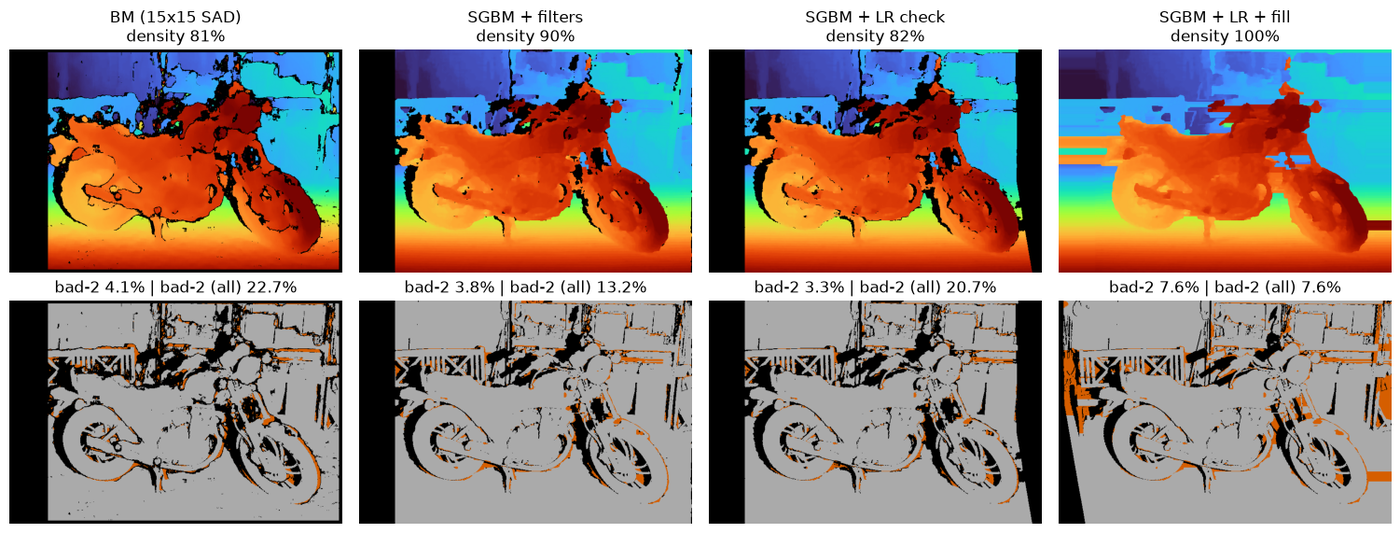

In [8]:
# --- Disparity and error maps for Motorcycle ---
# Error colours: grey = |err| <= 2 px, orange = |err| > 2 px, black = no prediction / no GT.
def error_map(d, gt, mask):
    out = np.zeros((*d.shape, 3), np.uint8)
    valid = mask & np.isfinite(d)
    err = np.abs(np.nan_to_num(d) - np.nan_to_num(gt))
    out[valid & (err <= 2)] = (170, 170, 170)
    out[valid & (err > 2)] = (213, 94, 0)
    return out

show = ["BM (15x15 SAD)", "SGBM + filters", "SGBM + LR check", "SGBM + LR + fill"]
vmin, vmax = np.nanpercentile(pair.gt, 2), np.nanpercentile(pair.gt, 98)
fig, axes = plt.subplots(2, 4, figsize=(15, 5.6))
for k, name in enumerate(show):
    m = stereo_df[(stereo_df.scene == "Motorcycle") & (stereo_df.method == name)].iloc[0]
    axes[0, k].imshow(viz.colorize_depth(maps[name], vmin=vmin, vmax=vmax))
    axes[0, k].set_title(f"{name}\ndensity {m['density']:.0%}")
    axes[1, k].imshow(error_map(maps[name], pair.gt, pair.nocc))
    axes[1, k].set_title(f"bad-2 {m['bad-2']:.1f}% | bad-2 (all) {m['bad-2 (all)']:.1f}%")
    for ax in axes[:, k]:
        ax.axis("off")
viz.savefig(fig, PROJECT, "sgbm_motorcycle")
plt.show()

### Window size

The block size trades robustness against edge fidelity. We sweep it for SGBM (with the
standard filters) over all 15 scenes; $P_1, P_2$ scale with the block area, so large
blocks also increase the smoothness penalties. Two controls help to interpret the sweep:
the same blocks with $P_1, P_2$ **held at their 5x5 values**, and OpenCV's three SGBM
modes (`MODE_SGBM_3WAY`, the default here; `MODE_SGBM`, 5 paths; `MODE_HH`, all 8 paths).

In [9]:
# --- SGBM block-size sweep over all training scenes (+ fixed-penalty and mode controls) ---
# Every entry is the mean bad-2 / density / EPE over the 15 scenes (non-occluded pixels).
def mean_metrics(**kw):
    vals = [M.disparity_metrics(M.stereo_sgbm(p.left, p.right, p.ndisp, **kw), p.gt, p.nocc)
            for p in pairs.values()]
    return {k: float(np.mean([v[k] for v in vals])) for k in ("density", "bad-2", "bad-2 (all)", "epe")}

pairs = {s: M.load_middlebury(s) for s in SCENES}
P1_5, P2_5 = 8 * 3 * 5**2, 32 * 3 * 5**2  # the default penalties of a 5x5 block
MODES = {"3WAY": cv2.STEREO_SGBM_MODE_SGBM_3WAY, "SGBM (5 paths)": cv2.STEREO_SGBM_MODE_SGBM,
         "HH (8 paths)": cv2.STEREO_SGBM_MODE_HH}
sweep_rows, mode_rows = [], []
for block in (1, 3, 5, 7, 9, 11, 13):
    row = {"block": block, **mean_metrics(block=block)}
    row["bad-2, P1/P2 of 5x5"] = mean_metrics(block=block, p1=P1_5, p2=P2_5)["bad-2"]
    sweep_rows.append(row)
    if block in (5, 9, 11):
        for mode_name, mode in MODES.items():
            mode_rows.append({"block": block, "mode": mode_name, "bad-2": mean_metrics(block=block, mode=mode)["bad-2"]})
sweep_df = pd.DataFrame(sweep_rows)
mode_df = pd.DataFrame(mode_rows).pivot(index="mode", columns="block", values="bad-2")
display(mode_df.round(2))
sweep_df.round(3)

block,5,9,11
mode,,,
3WAY,9.44,11.63,18.39
HH (8 paths),9.20,7.61,19.04
SGBM (5 paths),10.29,11.13,20.25


,block,density,bad-2,bad-2 (all),epe,"bad-2, P1/P2 of 5x5"
0,1,0.808,9.067,26.222,1.415,27.853
1,3,0.826,8.783,24.341,1.351,10.977
2,5,0.830,9.440,24.583,1.465,9.440
3,7,0.833,10.329,25.029,1.608,9.742
4,9,0.836,11.634,25.795,1.848,10.460
5,11,0.776,18.387,36.321,3.449,12.212
6,13,0.614,32.648,58.241,7.135,17.099


## 4. From disparity to depth and a point cloud

With $Z = fB/(d + d_\text{offs})$, a disparity error $\delta d$ causes a depth error

$$\delta Z \approx \frac{Z^2}{f\,B}\,\delta d ,$$

so the same sub-pixel matching accuracy gives quadratically worse depth at longer range.

We back-project the left-right-checked SGBM disparity of Motorcycle (no hole filling,
so only measured pixels) with `cvlab.pointcloud.depth_to_points`,
$X = Z\,K^{-1}[u, v, 1]^\top$. To *see* the 3D structure we render the coloured cloud into
virtual cameras that orbit the scene by ±25° (a z-buffered point splatting, the same
projection equation as before). White areas are surfaces the left camera never saw, plus
the pixels rejected by the left-right check.

276498 points, depth 2.01..4.43 m


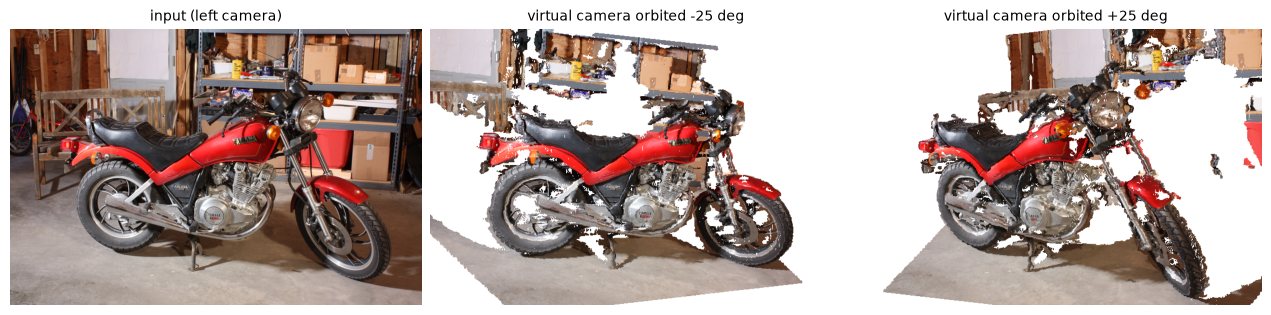

In [10]:
# --- Back-project to a coloured point cloud and render it from novel viewpoints ---
d_lr = maps["SGBM + LR check"]
depth = M.disparity_to_depth(d_lr, f, B, doffs) / 1000.0  # metres
pts, cols = depth_to_points(depth, K0, rgb=pair.left)
print(f"{len(pts)} points, depth {np.nanmin(depth):.2f}..{np.nanmax(depth):.2f} m")
pivot = np.array([0.0, 0.0, np.nanmedian(depth)])  # orbit around the scene centre
novel = {t: M.render_point_cloud(pts, cols, K0, M.orbit_pose(t, pivot), W, H) for t in (-25, 25)}
fig = viz.show_images([pair.left, novel[-25], novel[25]],
                      ["input (left camera)", "virtual camera orbited -25 deg",
                       "virtual camera orbited +25 deg"], ncols=3, size=4.2)
viz.savefig(fig, PROJECT, "stereo_point_cloud")
plt.show()

# Small thumbnail for the root README table (input | novel view).
thumb = viz.show_images([pair.left, novel[-25]], ncols=2, size=2.0)
viz.savefig(thumb, PROJECT, "thumb", dpi=100)
plt.close(thumb)

Now the error budget: the binned median depth error against the $Z^2$ model, with
$\delta d$ estimated robustly from the disparity residuals (1.4826 × median absolute
deviation; the median of $|\mathcal{N}(0, \sigma_Z)|$ is $0.674\,\sigma_Z$).

robust disparity noise sigma_d = 0.257 px


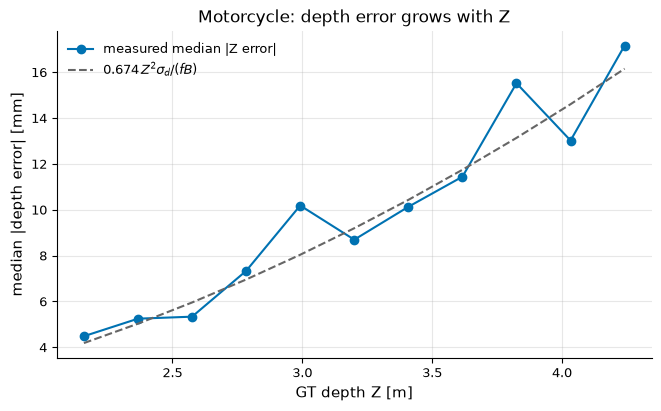

In [11]:
# --- Depth error vs depth on non-occluded pixels ---
valid = pair.nocc & np.isfinite(d_lr)
res_d = (d_lr - pair.gt)[valid]
sigma_d = 1.4826 * np.median(np.abs(res_d - np.median(res_d)))
z_gt, z_err = gt_depth[valid], np.abs(depth - gt_depth)[valid]
bins = np.linspace(np.percentile(z_gt, 1), np.percentile(z_gt, 99), 12)
centers = 0.5 * (bins[1:] + bins[:-1])
idx = np.digitize(z_gt, bins) - 1
med_err = np.array([np.median(z_err[idx == k]) for k in range(len(centers))])
pred = 0.6745 * centers**2 / (f * B / 1000.0) * sigma_d
print(f"robust disparity noise sigma_d = {sigma_d:.3f} px")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(centers, 1000 * med_err, "o-", label="measured median |Z error|")
ax.plot(centers, 1000 * pred, "--", color="0.4", label=r"$0.674\,Z^2\sigma_d/(fB)$")
ax.set(xlabel="GT depth Z [m]", ylabel="median |depth error| [mm]",
       title="Motorcycle: depth error grows with Z")
ax.legend()
plt.show()

## Results

All numbers were measured in this notebook on the 15 MiddEval3 training scenes at quarter
resolution (CPU: Intel Core Ultra 9 275HX; OpenCV 5.0).

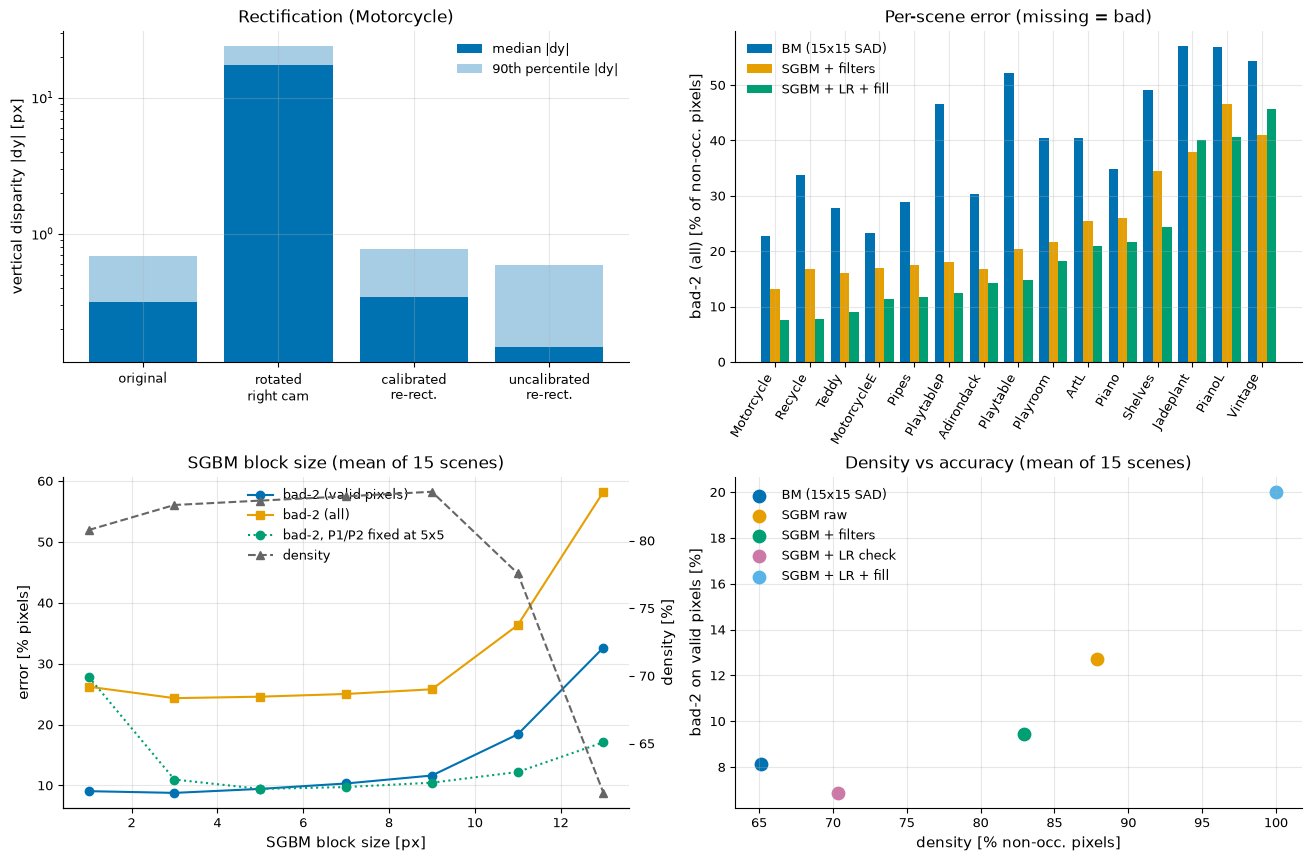

In [12]:
# --- Summary figure: rectification, per-scene accuracy, block size, density/accuracy ---
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))
ax[0, 0].bar(range(len(rect_df)), rect_df["median |dy| [px]"], color=viz.color(0, unit=True),
             label="median |dy|")
ax[0, 0].bar(range(len(rect_df)), rect_df["p90 |dy| [px]"], color=viz.color(0, unit=True),
             alpha=0.35, label="90th percentile |dy|")
ax[0, 0].set_xticks(range(len(rect_df)), ["original", "rotated\nright cam", "calibrated\nre-rect.",
                                          "uncalibrated\nre-rect."])
ax[0, 0].set(yscale="log", ylabel="vertical disparity |dy| [px]", title="Rectification (Motorcycle)")
ax[0, 0].legend()
piv = stereo_df.pivot(index="scene", columns="method", values="bad-2 (all)")[VARIANTS]
piv = piv.sort_values("SGBM + LR + fill")
xs = np.arange(len(piv))
for k, name in enumerate(["BM (15x15 SAD)", "SGBM + filters", "SGBM + LR + fill"]):
    ax[0, 1].bar(xs + (k - 1) * 0.27, piv[name], width=0.27, label=name, color=viz.color(k, unit=True))
ax[0, 1].set_xticks(xs, piv.index, rotation=60, ha="right")
ax[0, 1].set(ylabel="bad-2 (all) [% of non-occ. pixels]", title="Per-scene error (missing = bad)")
ax[0, 1].legend()
ax[1, 0].plot(sweep_df.block, sweep_df["bad-2"], "o-", label="bad-2 (valid pixels)")
ax[1, 0].plot(sweep_df.block, sweep_df["bad-2 (all)"], "s-", label="bad-2 (all)")
ax[1, 0].plot(sweep_df.block, sweep_df["bad-2, P1/P2 of 5x5"], "o:", label="bad-2, P1/P2 fixed at 5x5")
ax2 = ax[1, 0].twinx()
ax2.plot(sweep_df.block, 100 * sweep_df.density, "^--", color="0.4", label="density")
ax2.set_ylabel("density [%]")
ax2.grid(False)
ax[1, 0].set(xlabel="SGBM block size [px]", ylabel="error [% pixels]",
             title="SGBM block size (mean of 15 scenes)")
h1, l1 = ax[1, 0].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax[1, 0].legend(h1 + h2, l1 + l2, loc="upper center")
for k, name in enumerate(VARIANTS):
    ax[1, 1].scatter(100 * mean_df.loc[name, "density"], mean_df.loc[name, "bad-2"], s=80,
                     color=viz.color(k, unit=True), label=name)
ax[1, 1].set(xlabel="density [% non-occ. pixels]", ylabel="bad-2 on valid pixels [%]",
             title="Density vs accuracy (mean of 15 scenes)")
ax[1, 1].legend()
viz.savefig(fig, PROJECT, "stereo_summary")
plt.show()

The summary tables: mean metrics of the five matcher variants over the 15 scenes, and the
rectification experiment on Motorcycle. Everything is also written to
`results/nb02_stereo.json`.

In [13]:
# --- Summary tables (saved to results/nb02_stereo.json) ---
summary_df = mean_df.reset_index().rename(columns={"time_ms": "time per pair [ms]"})
save_json({"rectification": rect_rows, "per_scene": stereo_rows, "mean": summary_df.to_dict("records"),
           "block_sweep": sweep_rows, "sgbm_modes": mode_rows, "sigma_d_px": sigma_d}, RESULTS_DIR / "nb02_stereo.json")
display(summary_df.round(3))
display(rect_df.round(4))

,method,density,bad-1,bad-2,bad-2 (all),bad-0.5 (all),epe,time per pair [ms]
0,BM (15x15 SAD),0.651,11.810,8.133,39.924,47.453,1.391,7.000
1,SGBM raw,0.879,17.180,12.703,23.106,34.655,2.115,10.936
2,SGBM + filters,0.830,13.707,9.440,24.583,35.336,1.465,13.388
3,SGBM + LR check,0.704,10.836,6.875,34.349,43.217,1.048,44.564
4,SGBM + LR + fill,1.000,26.355,20.018,20.018,36.163,3.200,44.564


,pair,median |dy| [px],p90 |dy| [px],SGBM density,depth AbsRel,depth within 1%,GT pixels covered
0,original (rectified by Middlebury),0.3156,0.6831,0.8368,0.0095,0.9138,0.9024
1,rotated right camera,17.3183,24.0505,0.2508,0.4145,0.0057,0.2587
2,calibrated re-rectification,0.3459,0.7804,0.7878,0.0096,0.9065,0.7147
3,uncalibrated re-rectification,0.1479,0.5885,0.8213,NaN,NaN,NaN


**Takeaways**

* A rotation of about 2° of one camera is enough to destroy row alignment (a median
  vertical disparity of more than 17 px) and with it SGBM: the matcher only searches
  along rows. Calibrated re-rectification (`stereoRectify`) restores sub-pixel alignment
  *and* metric depth (AbsRel back at the level of the original pair, on fewer pixels
  because the re-rectified views overlap less); uncalibrated rectification from $F$ also
  aligns rows but gives no metric scale.
* SGBM is far denser than block matching and, counting missing pixels as errors, far more
  accurate, for 1.5-2 times BM's runtime on these quarter-resolution images. On the pixels
  BM does return, its error is similar to SGBM's: BM simply refuses the hard pixels. Both
  take a few tens of milliseconds or less per pair on the CPU (table above), and the
  left-right check more than triples SGBM's cost because the right view is matched too.
* Small SGBM windows (3x3 to 5x5) work best on average. From 11x11 the errors jump in all
  three OpenCV SGBM modes. Holding $P_1, P_2$ at their 5x5 values softens the jump at
  11x11, but the error still climbs steeply at 13x13. The growing smoothness penalties
  explain only part of it; the rest is a property of OpenCV's large-window cost
  aggregation that we did not investigate further.
* Post-processing is about choosing a point on the density/accuracy curve: the left-right
  check discards most wrong pixels (occlusions), and background-favouring hole filling
  gives a dense map with the lowest "bad-2 (all)".
* Per scene (filled SGBM), Vintage, PianoL (lighting changes between the two views),
  Jadeplant (thin branches, large disparity range) and Shelves (textureless, repetitive)
  are the hardest; well-textured Motorcycle, Recycle and Teddy are the easiest.
* Depth error grows quadratically with depth; the measured median error follows the
  $Z^2\sigma_d/(fB)$ model. For a robot, this sets the useful range of a stereo head
  given its baseline. The novel-view renderings show what a single stereo pair cannot
  provide: surfaces hidden from the left camera stay empty.

## Exercises

Solutions: `projects/09_multiview_geometry/solutions/solutions_02.py`.

**Exercise 1: tune SGBM.** Grid-search the uniqueness ratio (0, 5, 10, 15) and the $P_2/P_1$
ratio (2, 4, 8) on Motorcycle, Piano and Jadeplant, scoring "bad-2 (all)" after LR check +
hole filling. Do the best settings transfer between scenes?

In [14]:
# --- Exercise 1: SGBM parameter search (TODO) ---
# TODO: build cv2.StereoSGBM_create(...) with P1 = 8*3*b^2 and P2 = ratio * P1, run the
#       LR check + M.fill_holes, and collect M.disparity_metrics(...)["bad-2 (all)"].

**Exercise 2: your own block matcher.** Build a SAD cost volume $C(y, x, d)$ in NumPy for Teddy
(grayscale, $d \in [0, \text{ndisp})$), aggregate it with a box filter (`cv2.blur`) of size
$b \times b$, take the winner-takes-all disparity and compare its bad-2/density with
`cv2.StereoBM` and with SGBM. Add sub-pixel refinement by fitting a parabola through the
costs at $d-1, d, d+1$.

In [15]:
# --- Exercise 2: NumPy winner-takes-all block matching (TODO) ---
# TODO: cost[d] = cv2.blur(|L(x) - R(x - d)|, (b, b)); disp = argmin_d cost; parabola fit.

**Exercise 3: photometric robustness.** `MotorcycleE` has the same geometry as `Motorcycle`
but the right image was taken with a different exposure, and `PianoL` with different lighting.
Compare SGBM's errors on the pairs and explain the result. Then try a census transform
(compare bit strings of a 7x7 neighbourhood with the Hamming distance) as the matching cost
in your matcher from exercise 2.

In [16]:
# --- Exercise 3: exposure / lighting changes (TODO) ---
# TODO: compare M.disparity_metrics for Motorcycle vs MotorcycleE and Piano vs PianoL.